# Etapa 01: La base de muestras, su limpieza y lo que vimos en ella

Este notebook tiene dos partes. En la parte A contamos qué pregunta queríamos responder, qué columnas esperamos de
la base del laboratorio (y en qué momento del proceso se conoce cada una) y dejamos guardadas las tablas crudas tal
como llegan, sin limpiar nada todavía. En la parte B las limpiamos con reglas fijas dejando constancia de cada
corrección, las juntamos en una sola tabla por muestra y exploramos el periodo de desarrollo (entrenamiento y
validación) sin mirar el bloque de prueba.

[Notebook completo](Proyecto_Final.ipynb)<br>Siguiente: [Etapa 02: Base real](02_base_real.ipynb) →

## Código del proyecto

La celda siguiente prepara el código del proyecto. En una copia del repositorio no hace nada y en Google Colab trae el paquete `proyecto/` desde `notebooks/codigo/` (si se subió junto al notebook) o desde el repositorio, así que basta con ejecutar todo (*Entorno de ejecución → Ejecutar todas*). La sección se puede plegar desde su título.

In [ ]:
# Código del proyecto (67 archivos, 215 kB): el paquete proyecto/ (56 módulos) y el mapeo de columnas.
# En una copia del repositorio o en la carpeta de la entrega ya está y no se toca nada.
# En Colab se extrae de codigo/01_datos_exploracion.tar.xz si se subió junto al notebook o se descarga
# del repositorio; en los dos casos se comprueba su huella SHA-256 antes de extraerlo.
# Un archivo local con otro contenido se conserva (SOBRESCRIBIR = True lo reemplaza).
import hashlib, importlib, io, os, sys, tarfile, urllib.request
from pathlib import Path

ARCHIVO, HUELLA, SOBRESCRIBIR = "01_datos_exploracion.tar.xz", "4aedd4326d8693da2447909404ab97e842715368a5cb81477469c9bbf6ffdafe", False
URL = "https://raw.githubusercontent.com/Over-HCV/ML-I/main/content/docs/final-project/notebooks/codigo/" + ARCHIVO

if Path.cwd().name == "notebooks" and Path("../proyecto/__init__.py").exists():
    os.chdir("..")  # abierto desde notebooks/: se trabaja en la raíz del proyecto


def recrear_proyecto():
    origen = next((Path(d) / ARCHIVO for d in ("notebooks/codigo", "codigo", ".") if (Path(d) / ARCHIVO).exists()), None)
    if origen is None and Path("proyecto/__init__.py").exists():
        escritos, iguales, conservados = 0, None, []
    else:
        datos = origen.read_bytes() if origen else urllib.request.urlopen(URL, timeout=60).read()
        if hashlib.sha256(datos).hexdigest() != HUELLA:
            raise ValueError(f"{ARCHIVO} no corresponde a este notebook: su SHA-256 no coincide.")
        escritos, iguales, conservados = 0, 0, []
        with tarfile.open(fileobj=io.BytesIO(datos), mode="r:xz") as archivo:
            for miembro in archivo.getmembers():
                destino = Path(miembro.name)
                if destino.is_absolute() or ".." in destino.parts:
                    raise ValueError(f"Ruta no permitida en el archivo: {miembro.name}")
                contenido = archivo.extractfile(miembro).read()
                if destino.exists() and destino.read_bytes() == contenido:
                    iguales += 1
                elif destino.exists() and not SOBRESCRIBIR:
                    conservados.append(miembro.name)
                else:
                    destino.parent.mkdir(parents=True, exist_ok=True)
                    destino.write_bytes(contenido)
                    escritos += 1
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    importlib.invalidate_caches()
    print("Código del proyecto:", "se usa la copia local." if iguales is None
          else f"{escritos} archivos escritos, {iguales} ya estaban iguales.")
    if conservados:
        print(f"Se conservaron {len(conservados)} archivos locales distintos:", ", ".join(conservados))


recrear_proyecto()

## Desarrollo de la etapa

In [1]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import datos

iniciar_etapa("01_datos_exploracion")
c = datos.iniciar()
mostrar(c.encabezado, c.autores)

## Parte A: El problema y la base de muestras

## 1. El problema

Un laboratorio de microbiología recibe todos los días muestras de producto terminado, materia prima, agua y
muestreos en planta de clientes cosméticos, farmacéuticos, de alimentos, veterinarios y de centrales de mezclas.
De cada muestra guarda quién la envió, cómo llegó, qué ensayo se le hizo, quién la procesó y qué resultado dio. El
contexto es el de Rodam Análisis SAS en Bogotá, aunque lo que estudiamos es la base de muestras y no la empresa.
Con esa base nos propusimos tres preguntas:

a. **Demanda.** Cuántas muestras van a llegar, para programar analistas, medios de cultivo e incubadoras.
b. **Riesgo.** Qué tan probable es que una muestra salga no conforme (fuera del límite que exige la norma) y, si
   sale positiva, qué tan probable es que sea un falso positivo.
c. **Grupos.** Qué clientes o muestras se parecen entre sí.

De cada pregunta salían varios análisis posibles y no nos daba el tiempo para estudiarlos todos a fondo. Por eso
armamos un catálogo de candidatos, los pasamos por la misma prueba rápida en la etapa 03 y solo a los ganadores
los modelamos en serio.

## 2. El contrato de datos

Antes de tener datos escribimos un contrato (`proyecto/datos/esquema.py`), que es el único lugar del código
donde aparecen los nombres de las columnas. De cada columna dice su tipo, su papel, si es obligatoria y el
**momento** del proceso en que el dato pasa a conocerse (la toma, la llegada, la recepción, la lectura...). Si
la exportación real no trae una columna opcional, los análisis que la usan simplemente se omiten.

In [2]:
datos.contrato(c).mostrar()

Columna,Tipo,Papel,Momento,Obligatoria,Descripción
id_cliente,id,id,maestro,sí,Identificador del cliente
sector,categoria,variable,maestro,sí,Línea de negocio del cliente
zona,categoria,variable,maestro,no,Municipio o zona de la planta
tamano,categoria,variable,maestro,no,Tamaño de la empresa
tipo_contrato,categoria,variable,maestro,no,Contrato marco o servicio por demanda
certificacion_bpm,categoria,variable,maestro,no,Cuenta con certificación BPM (sí/no)
plan_muestreo,categoria,variable,maestro,no,Frecuencia pactada de muestreo en planta
fecha_vinculacion,fecha,fecha,maestro,no,Fecha de vinculación como cliente
distancia_km,numero,variable,maestro,no,Distancia de la planta al laboratorio (km)
canal_captacion,categoria,variable,maestro,no,Canal por el que llegó el cliente


El momento es lo que más adelante nos protege de la fuga de información, que es usar para predecir un dato que
todavía no existe en el instante de la predicción. Cada análisis declara en qué momento predice y solo puede
usar las columnas conocidas hasta ahí. Así se lo preguntamos al contrato para una predicción en la recepción:

In [3]:
from proyecto.datos import esquema
from proyecto.reporte.html import fichas

al_recibir = esquema.columnas("muestras", hasta="recepcion")   # lo que ya se sabe cuando la muestra llega
despues = [x for x in esquema.columnas("muestras") if x not in al_recibir]
mostrar(fichas(al_recibir, f"{len(al_recibir)} columnas de muestras que se conocen al recibirla"),
        fichas(despues, f"{len(despues)} que llegan después y quedan prohibidas para esa predicción", color="rojo"))

## 3. Las tablas crudas

Obtenemos las tablas, las validamos contra el contrato (si falta una columna obligatoria la etapa se detiene y
dice cuáles) y las guardamos tal como llegan, en CSV. Así la limpieza de la parte B queda como un paso aparte
que se puede auditar.

In [4]:
datos.tablas_crudas(c).mostrar()

Bastó con mirar las tablas para ver que hacía falta un paso de limpieza: La misma categoría escrita de varias
formas, recuentos reportados como texto, valores imposibles y filas repetidas.

In [5]:
datos.como_llegan(c).mostrar()

## 4. La base real y su complemento simulado

La base del proyecto es la exportación real del laboratorio, que consiguió Daniel y que trabajamos en el notebook 02.
Trae lo que registra el sistema (cliente, sector, origen, análisis, lecturas y dictamen) pero no trae los controles
de calidad de cada ensayo ni los datos de recepción (temperatura, transporte, estado del envase) y varias técnicas
del curso los necesitan. Para complementarla armamos una base simulada con la misma estructura y esos campos.
Sobre ella aplicamos en los notebooks 03 a 06 el cribado, la regresión, la clasificación con umbral por costo, Bayes
con los controles, Taguchi, la red neuronal y el agrupamiento.

La base complementaria tiene además una ventaja: Conocemos la verdad. Las variables ocultas del simulador (si la
muestra estaba de verdad contaminada, qué tan higiénico es cada cliente) quedan aparte en `datos/auditoria/`, ningún
modelo las lee y nos sirven para comprobar si los modelos encuentran lo que de verdad hay. Las cifras de los notebooks
01 y 03 a 06 salen de esta base complementaria y las del notebook 02 de la real. El mismo código puede leer la exportación
real en estos notebooks con solo describir en `configuracion/mapeo_columnas.json` cómo se llama cada columna y fijar
`PROYECTO_ORIGEN=real`.

In [6]:
datos.exportacion_real(c).mostrar()

Tabla de auditoría,Filas,Columnas latentes
verdad_muestras,38846,"contaminada_real, prob_contaminacion, prob_falso_positivo, positivo_sin_ruido, en_episodio, logit_contaminacion"
verdad_clientes,220,"segmento_latente, higiene, tasa_semanal, fecha_retiro"
verdad_ensayos,7,"ensayo, sensibilidad, especificidad_nominal, especificidad_efectiva, prevalencia_real"


## 5. Protocolo de evaluación y mapa del proyecto

Partimos la base por tiempo con cortes que fijamos en `config` antes de ver un solo resultado. El
**entrenamiento** sirve para ajustar y comparar modelos (con validación cruzada de ventana creciente, que
explicamos en la parte B), la **validación** para decidir (el umbral, el modelo que se congela) y la **prueba**
se guarda aparte y solo se abre una vez, en la etapa 06. Las etapas se pasan la información únicamente por
archivos en disco.

In [7]:
datos.protocolo(c).mostrar()

In [8]:
datos.terminar(c)   # cierra la parte A; la etapa sigue abierta para la parte B

## Parte B: Limpieza, integración y exploración

Aquí leemos las tablas crudas, las limpiamos con reglas fijas dejando constancia de cada corrección, las juntamos
en una sola tabla por muestra y exploramos el periodo de desarrollo (entrenamiento y validación) sin mirar el
bloque de prueba.

In [9]:
from proyecto.etapas import exploracion

c = exploracion.iniciar()   # la misma etapa: sus cifras se suman a las de la parte A

## 6. Limpieza con auditoría

La limpieza convierte tipos y fechas, unifica cómo se escriben las etiquetas, quita los duplicados exactos,
vuelve faltantes los valores imposibles, interpreta el recuento reportado (un número, una cota como "<10" o
presencia y ausencia) y corrige los resultados que contradicen su recuento. Cada problema queda en una tabla de
auditoría con las filas afectadas y lo que hicimos con ellas.

La corrimos sobre la tabla completa (antes de partirla por tiempo) porque sus reglas están escritas en el código
y no aprenden nada de los datos. Lo que sí se aprende de los datos (imputación, escalado, codificación) lo dejamos
dentro de las tuberías de cada modelo, ajustado solo con entrenamiento.

In [10]:
exploracion.limpieza_auditada(c).mostrar()

Tipo de problema,Columnas o reglas,Filas afectadas,Acción
etiquetas con grafía inconsistente,9,5077,"se unifican mayúsculas, tildes y espacios"
filas duplicadas exactas,1,148,se conserva una copia
valor imposible,4,365,se convierte en faltante
"""fecha_reporte"" anterior a ""fecha_recepcion""",1,39,"""fecha_reporte"" se convierte en faltante"
"recuento censurado (""<N"" o "">N"")",1,18816,"la cota queda en ""recuento_ufc"" y se marca ""recuento_censurado"" = 1"
recuento con unidad u otro texto,1,282,se extrae el número
resultado que contradice el recuento reportado,1,219,se corrige el resultado según el recuento y el límite
Tabla,Problema,Filas afectadas,Acción
clientes,"etiquetas con grafía inconsistente en ""sector""",9,"se unifican mayúsculas, tildes y espacios"
clientes,"etiquetas con grafía inconsistente en ""zona""",8,"se unifican mayúsculas, tildes y espacios"


## 7. Partición temporal

Cada muestra cae en un bloque según su fecha de recepción. De aquí en adelante **toda la exploración usa solo el
periodo de desarrollo** y del bloque de prueba únicamente contamos filas.

In [11]:
exploracion.particion_temporal(c).mostrar()

Bloque,Filas,Desde,Hasta,Porcentaje
entrenamiento,23151,2023-01-02,2025-06-27,59.6
validación,6748,2025-07-01,2025-12-31,17.4
prueba,8947,2026-01-02,2026-10-30,23.0


Dentro del entrenamiento tampoco podíamos validar mezclando fechas al azar porque eso deja que el modelo aprenda
de semanas posteriores a las que luego predice. Por eso usamos una validación cruzada de **ventana creciente**:
En cada bloque el modelo se ajusta con todo el pasado y se valida con el tramo que sigue y en el siguiente bloque
ese tramo pasa a ser parte del pasado. La función `bloques_temporales` arma esos cortes y la animación los
muestra uno por uno:


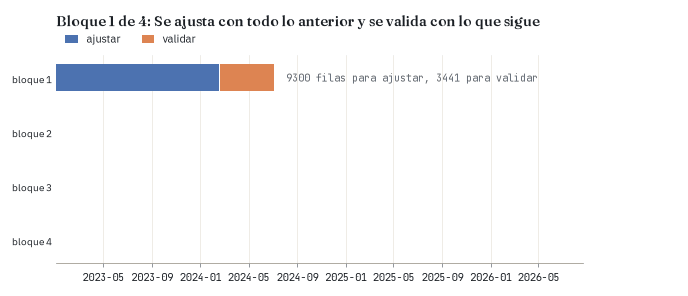
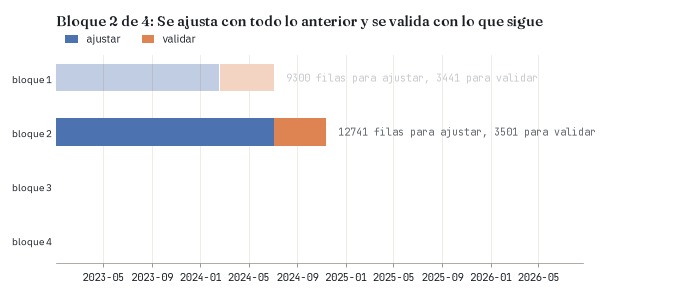
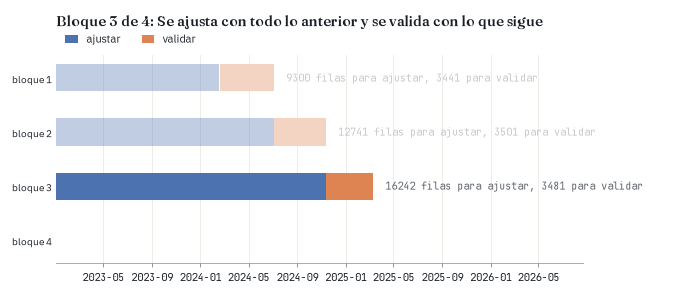
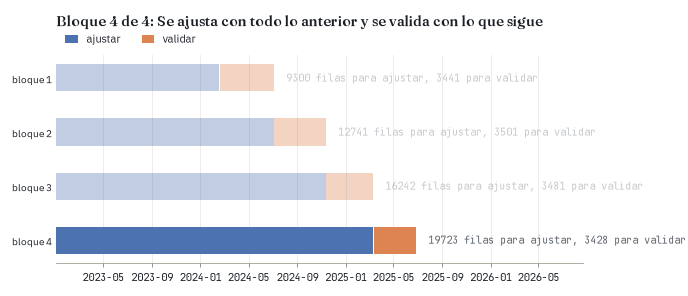

In [12]:
from proyecto.base import config
from proyecto.evaluacion import validacion
from proyecto.reporte.graficos_presentacion import animacion_bloques

entrenamiento = c.desarrollo[c.desarrollo["fecha_recepcion"] < config.CORTE_VALIDACION]
fechas = entrenamiento["fecha_recepcion"].reset_index(drop=True)
bloques = validacion.bloques_temporales(fechas)   # pares (ajustar, validar) que scikit-learn recibe como cv=
mostrar(animacion_bloques(fechas, bloques))

## 8. Faltantes

Separamos dos clases de faltantes. Los **estructurales** son datos que no pueden existir para esa fila (una
muestra rechazada no tiene resultado) y los **no estructurales** son datos que debieron registrarse y no se
registraron. Los primeros no los imputamos como si fueran olvidos y los segundos se imputan dentro de la tubería
de cada modelo.

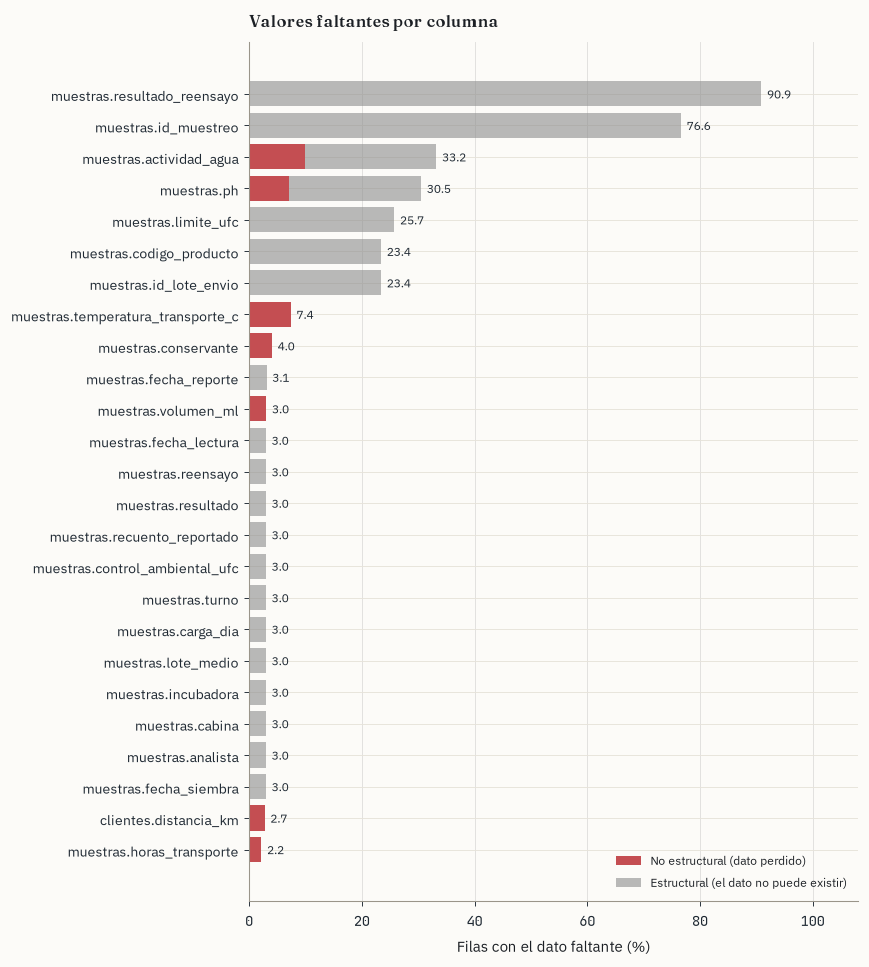

In [13]:
exploracion.faltantes(c).mostrar()

## 9. Volumen y estacionalidad

La primera pregunta es cuántas muestras van a llegar así que empezamos por el volumen semanal de cada línea de
negocio y por el patrón dentro del año.

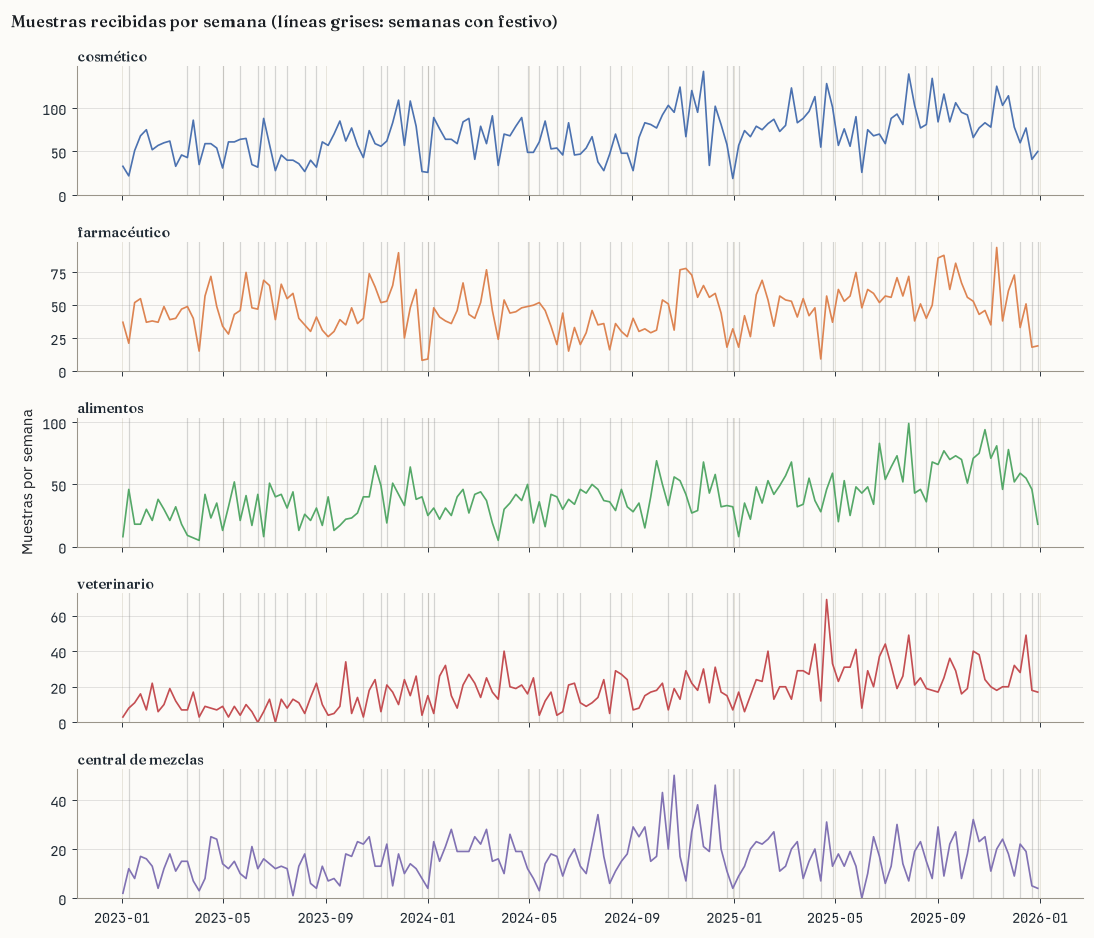

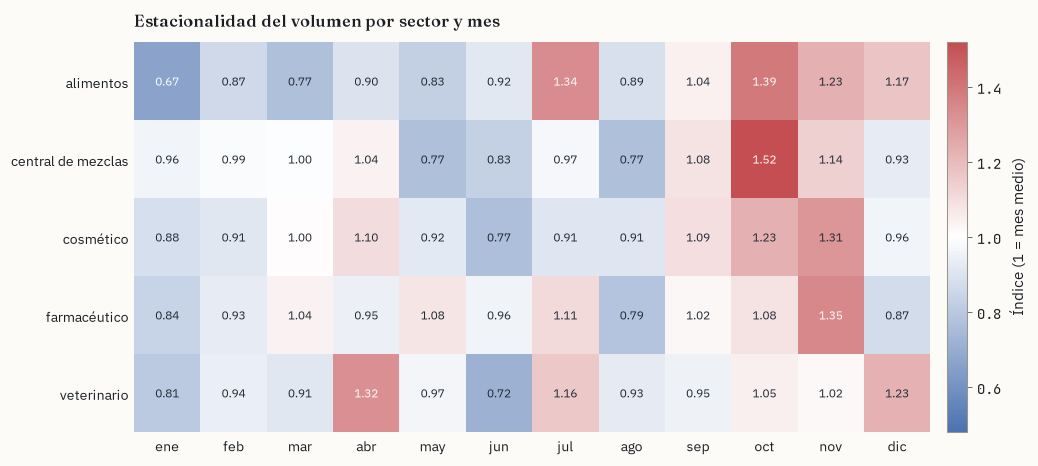

In [14]:
exploracion.volumen(c).mostrar()

## 10. Resultado no conforme

Una muestra es **no conforme** cuando su recuento supera el límite que exige la norma para ese producto. Miramos
qué tan frecuente es y cómo cambia por sector, matriz (el tipo de producto) y ensayo. Después miramos cómo se
relaciona con las variables numéricas que ya se conocen cuando la muestra llega.

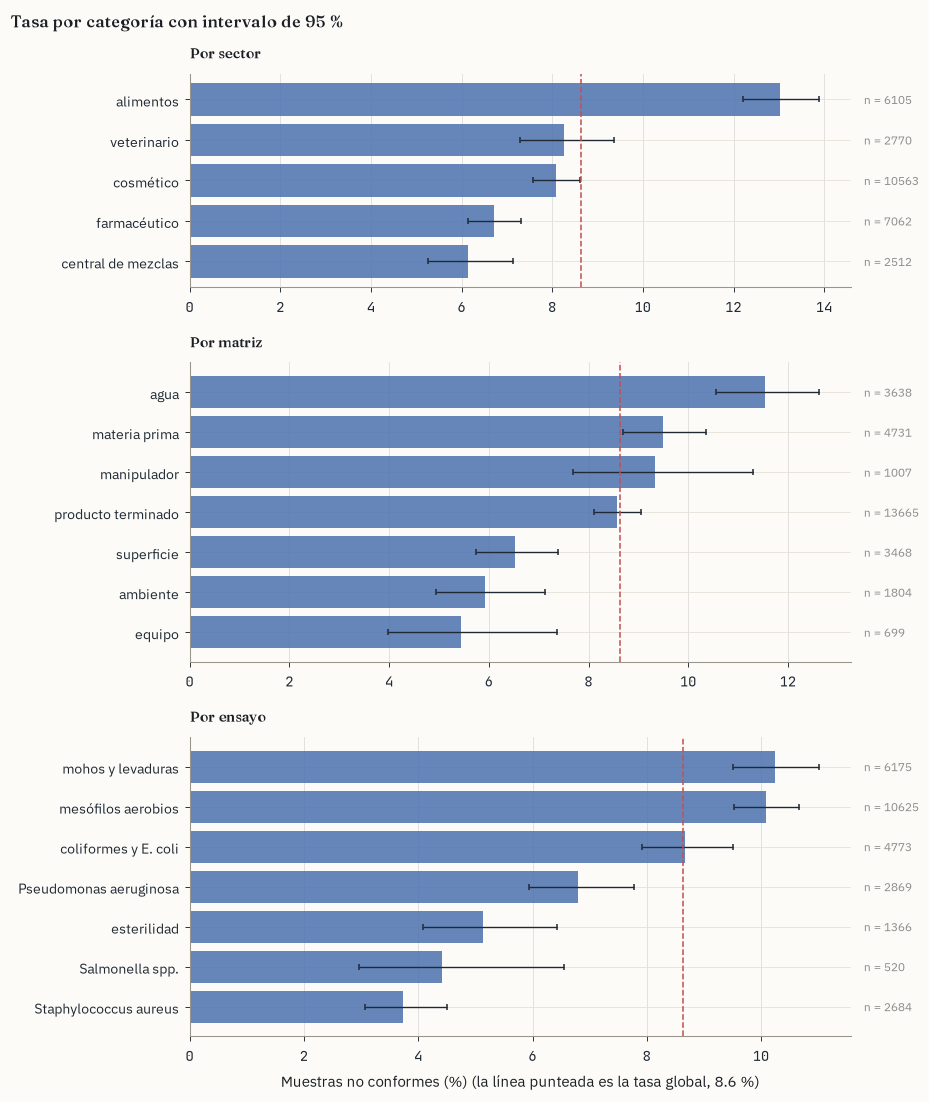

In [15]:
exploracion.tasa_no_conforme(c).mostrar()

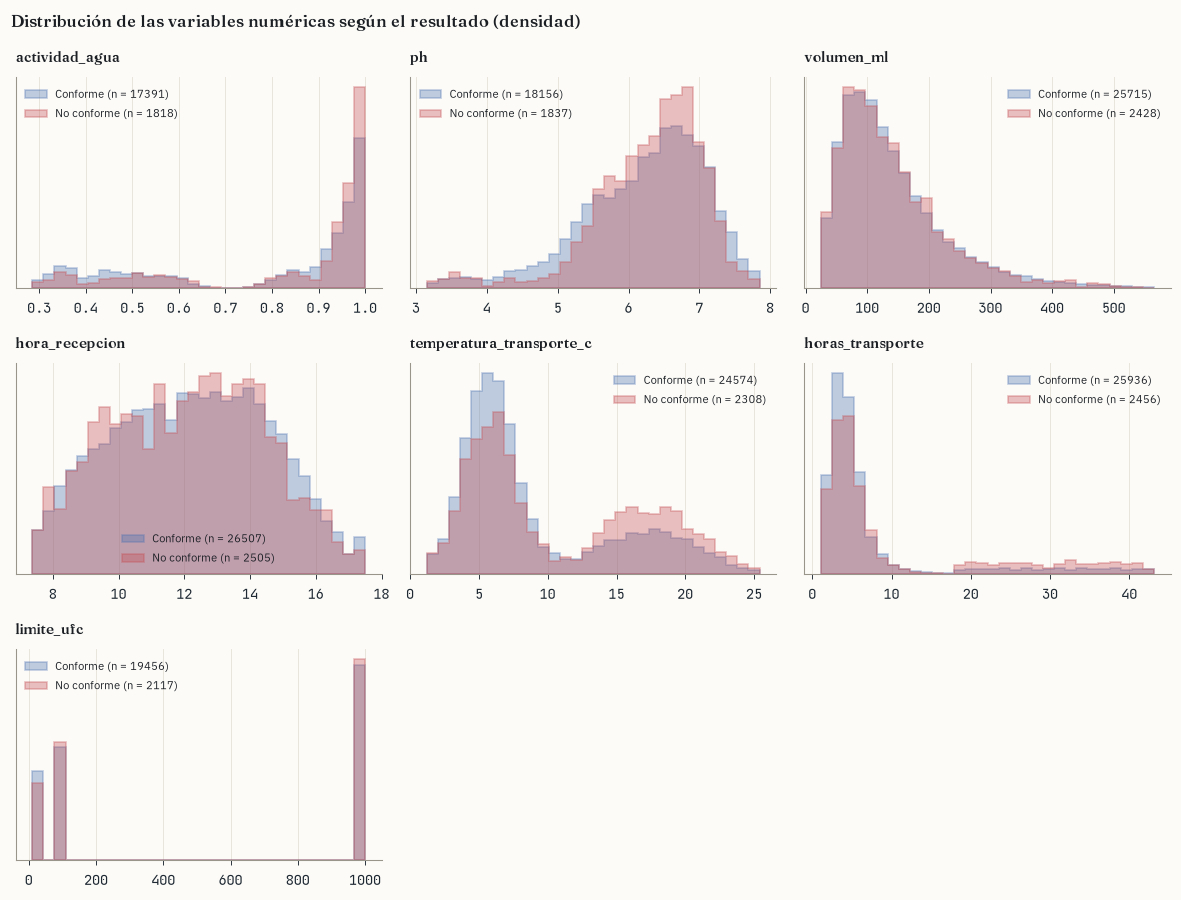

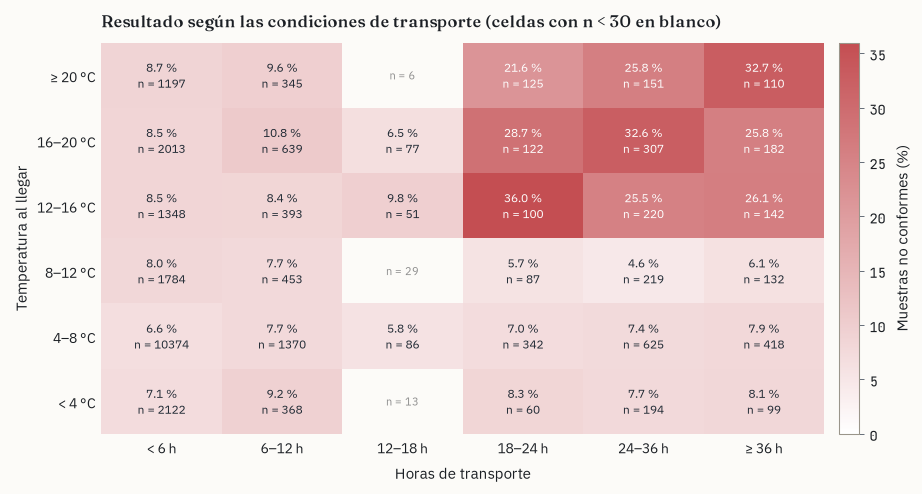

In [16]:
exploracion.distribuciones(c).mostrar()

## 11. Tiempos de entrega

El tiempo entre la recepción y el informe depende sobre todo de cuántos días incuba cada ensayo.

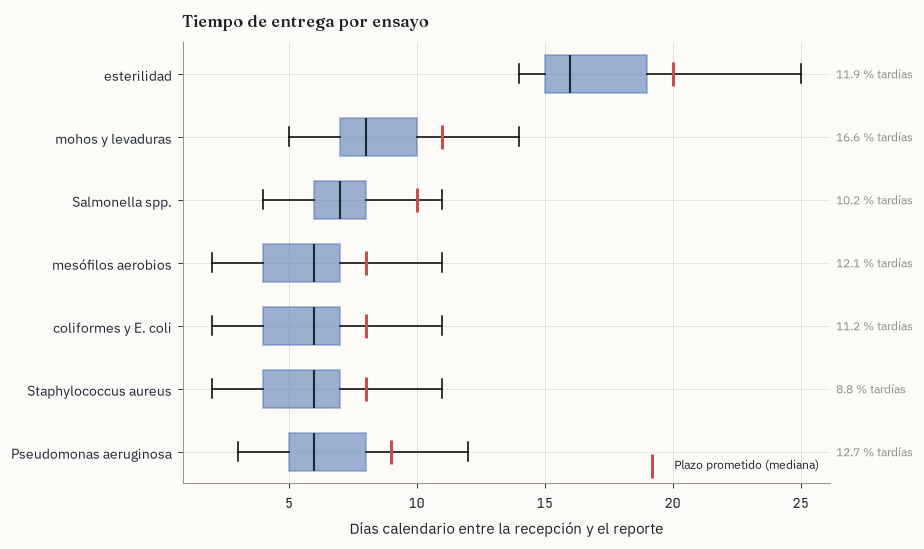

In [17]:
exploracion.entrega(c).mostrar()

## 12. Estabilidad en el tiempo

Un modelo ajustado con el pasado solo sirve si el futuro se le parece así que nos preguntamos si la tasa de no
conformes se mantiene mes a mes o si deriva (cambia de nivel con el tiempo).

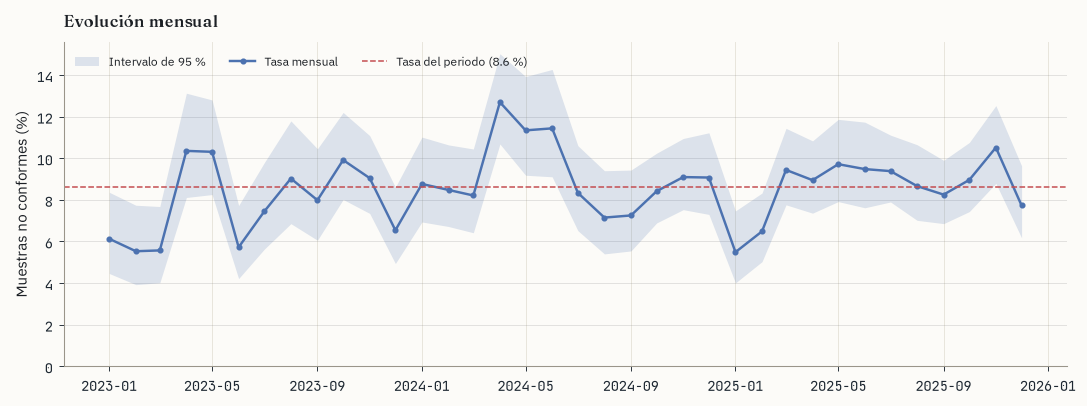

In [18]:
exploracion.estabilidad(c).mostrar()

## 13. Correlaciones entre variables numéricas

Usamos la correlación de Spearman, que mide si dos variables suben y bajan juntas aunque no sea en línea recta
(trabaja con el orden de los valores y no con los valores mismos). Va de menos uno a uno y la escribimos ρ. Con
ella buscamos variables redundantes y variables asociadas con los resultados.

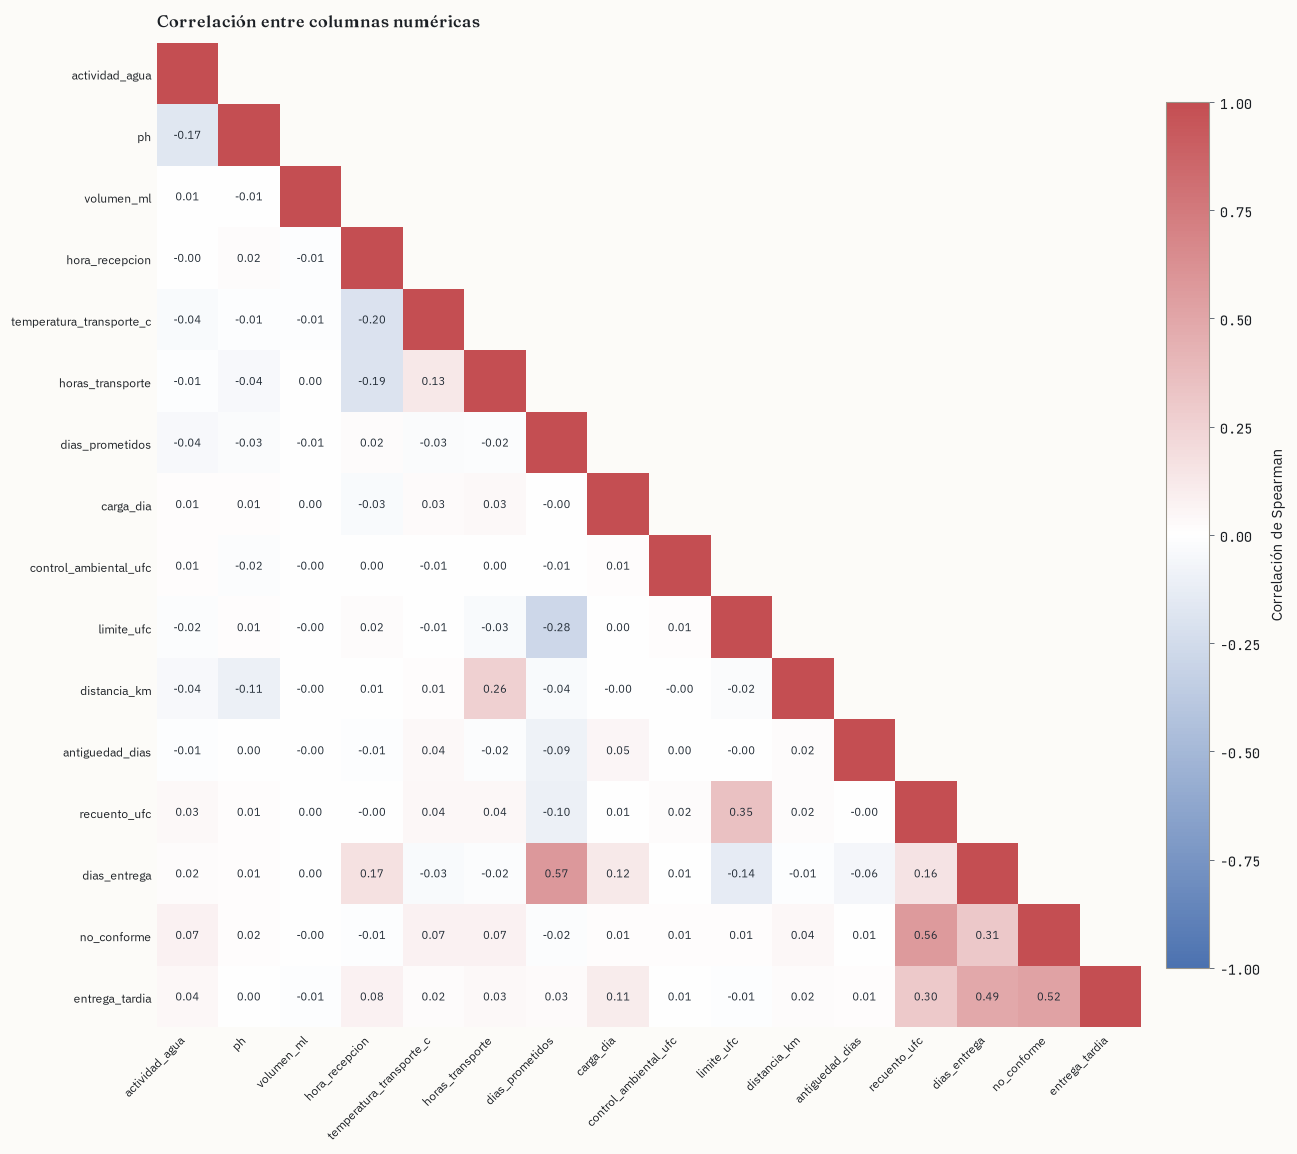

In [19]:
exploracion.correlaciones(c).mostrar()

## 14. Concentración del volumen por cliente

De cómo se distribuye el volumen entre clientes depende cuánta historia tiene cada uno y qué tan confiables son
las variables que construimos con su pasado.

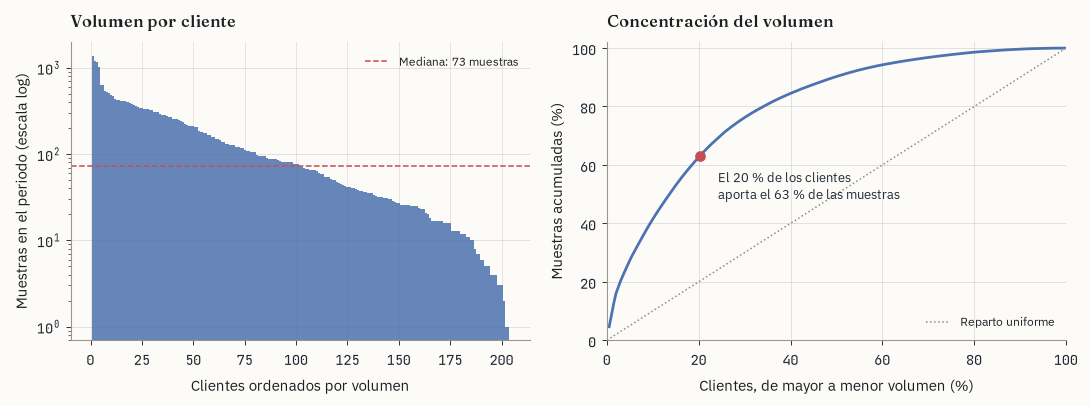

In [20]:
exploracion.concentracion(c).mostrar()

## 15. Lo que esto implica para el modelado

In [21]:
exploracion.implicaciones(c).mostrar()

In [22]:
exploracion.terminar(c)

[Notebook completo](Proyecto_Final.ipynb)<br>Siguiente: [Etapa 02: Base real](02_base_real.ipynb) →